# Part 1 — Training only (heavy recipe)

No ablations here: this notebook trains **one** configuration, so experiments are cheap to iterate.
The ablation study gets added back once the accuracy is good.

### What the previous run told us (`resnet_best`, 224px, 80 epochs, val 56.1%)

| observation | conclusion |
|---|---|
| train acc 99.9% @ epoch 51, val 56% | **overfitting is the bottleneck**, not capacity → stronger regularization, not a bigger net |
| `no_batchnorm` → 3.2% (−52.9) | BatchNorm is essential, keep |
| `no_augment` → 46.5% (−9.6) | augmentation works, but crop+flip alone is too weak |
| `no_se` → 57.5% (**+1.4**) | SE doesn't help here → removed |
| `no_residual` → 55.3% (−0.8) | residuals barely matter at 18 layers, but they cost nothing → kept |

### Changes in this recipe

| change | source |
|---|---|
| 320px input (was 224) | fine-grained variants differ in small details; resolution is the usual biggest lever |
| TrivialAugmentWide + RandomErasing | Müller & Hutter, ICCV 2021; Zhong et al., AAAI 2020 (lecture 6) |
| Mixup / CutMix (one per batch) | Zhang et al., ICLR 2018; Yun et al., ICCV 2019 (lecture 6) |
| stochastic depth p=0.1 | Huang et al., ECCV 2016 (lecture 6) |
| 300 epochs (was 80) | heavy augmentation converges much more slowly |
| EMA of the weights | Polyak averaging (lecture 6) |
| no SE | our own ablation |

## Setup

In [1]:
import os, json, time, math, random, copy
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from torchvision.datasets import FGVCAircraft
from torchvision.transforms import functional as TF
from torch.utils.data import Dataset, DataLoader, Subset, ConcatDataset
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# If the dataset download gets interrupted, delete DATA_ROOT and re-run:
# torchvision treats a half-extracted folder as a complete dataset.
DATA_ROOT = Path("/content/data") if IN_COLAB else Path.home() / "data" / "fgvc"
OUT_DIR = Path("/content/drive/MyDrive/ipcv") if IN_COLAB else Path(".")
RESULTS_DIR, CACHE_DIR = OUT_DIR / "results", OUT_DIR / "cache"
for d in (RESULTS_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
NUM_WORKERS = 4 if IN_COLAB else 0      # CPU augmentation would otherwise starve the GPU
print("device:", DEVICE, "| amp:", AMP)

Mounted at /content/drive
device: cuda | amp: True


## Config

One dict = one experiment. Change a value, re-run the notebook, compare in the results table at the end.

In [2]:
cfg = dict(
    name="resnet_heavy_320",
    seed=42,
    # data
    img_size=320,
    train_split="train",       # "trainval" doubles the data for the final model (val becomes useless then)
    crop_scale=(0.35, 1.0),
    trivial_augment=True,
    random_erasing=0.25,
    mixup_alpha=0.2,           # 0 disables
    cutmix_alpha=1.0,          # 0 disables; when both are on, one is picked per batch
    # architecture
    stage_blocks=(2, 2, 2, 2),
    stage_channels=(64, 128, 256, 512),
    residual=True,
    batchnorm=True,
    se=False,                  # ablation showed it hurts
    stoch_depth=0.1,
    dropout=0.3,
    # training
    epochs=300,
    batch_size=64,
    lr=0.05,                   # linear scaling rule: 0.1 is for batch 256, we use batch 64
    weight_decay=5e-4,
    warmup_epochs=5,
    label_smoothing=0.1,
    ema_decay=0.999,           # 0 disables
)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(cfg["seed"])

## Data

Images are decoded once into cached `uint8` tensors (~1 GB per split at 320px, stored on Drive), then augmented on the fly.

In [3]:
MEAN, STD = (0.488, 0.519, 0.544), (0.211, 0.203, 0.236)   # measured on the train split

def cached_split(split, img_size):
    f = CACHE_DIR / f"{split}_{img_size}.pt"
    if not f.exists():
        ds = FGVCAircraft(DATA_ROOT, split=split, annotation_level="variant", download=True)
        print(f"caching {split} ({len(ds)} images) ...", flush=True)
        imgs = [TF.pil_to_tensor(TF.resize(im.crop((0, 0, im.width, im.height - 20)), [img_size, img_size]))
                for im, _ in ds]
        torch.save((torch.stack(imgs), torch.tensor(ds._labels), ds.classes), f)
    return torch.load(f)

class Aircraft(Dataset):
    def __init__(self, split, cfg, train=False):
        self.x, self.y, self.classes = cached_split(split, cfg["img_size"])
        aug = []
        if train:
            aug = [T.RandomResizedCrop(cfg["img_size"], scale=cfg["crop_scale"], antialias=True),
                   T.RandomHorizontalFlip()]
            if cfg["trivial_augment"]:
                aug.append(T.TrivialAugmentWide())        # works on uint8 tensors
        post = [T.ConvertImageDtype(torch.float), T.Normalize(MEAN, STD)]
        if train and cfg["random_erasing"] > 0:
            post.append(T.RandomErasing(p=cfg["random_erasing"]))
        self.transform = T.Compose(aug + post)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.transform(self.x[i]), self.y[i]

def make_data(cfg):
    """train_split='trainval' trains on train+val (6667 images) for the final model."""
    if cfg["train_split"] == "trainval":
        train = ConcatDataset([Aircraft("train", cfg, train=True), Aircraft("val", cfg, train=True)])
    else:
        train = Aircraft("train", cfg, train=True)
    return train, Aircraft("val", cfg)

train_ds, val_ds = make_data(cfg)
CLASSES = Aircraft("val", cfg).classes
NUM_CLASSES = len(CLASSES)
print(f"classes: {NUM_CLASSES} | train {len(train_ds)} | val {len(val_ds)}")

100%|██████████| 2.75G/2.75G [01:28<00:00, 31.1MB/s]


caching train (3334 images) ...
caching val (3333 images) ...
classes: 100 | train 3334 | val 3333


A few augmented samples — check they are still recognizable aircraft.

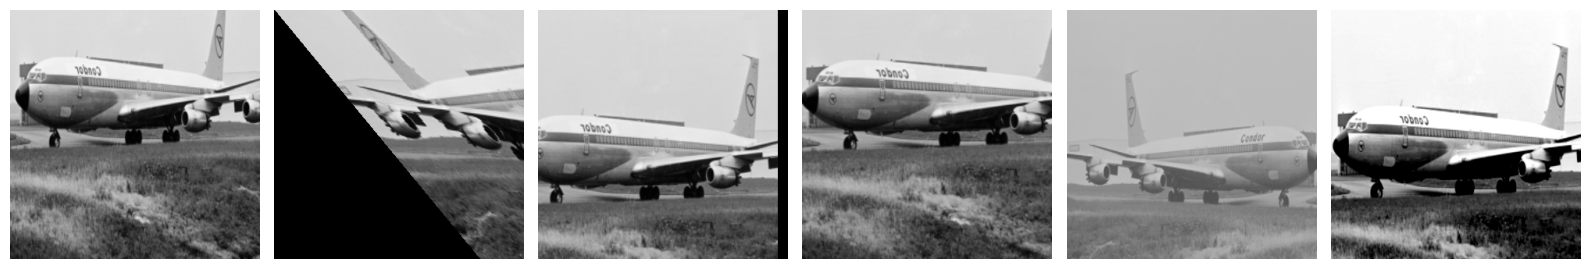

In [4]:
def show(t):
    return (t.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax in axes:
    ax.imshow(show(train_ds[0][0])); ax.axis("off")
plt.tight_layout(); plt.show()

## Model

ResNet-18 layout written from primitive layers (`nn.Conv2d`, `nn.BatchNorm2d`, `nn.Linear`) — no `torchvision.models`.

```
stem  3x3 s2 -> 3x3 -> 3x3 -> maxpool        320 -> 80
stage1  2 blocks C=64                         80
stage2  2 blocks C=128                        40
stage3  2 blocks C=256                        20
stage4  2 blocks C=512                        10
global avg pool -> dropout -> linear(512,100)
```

In [5]:
def conv_bn(c_in, c_out, k, stride, cfg):
    layers = [nn.Conv2d(c_in, c_out, k, stride=stride, padding=k // 2, bias=not cfg["batchnorm"])]
    if cfg["batchnorm"]:
        layers.append(nn.BatchNorm2d(c_out))
    return nn.Sequential(*layers)


class SEBlock(nn.Module):
    """Squeeze-and-Excitation (Hu et al. 2018) - kept available for ablations."""
    def __init__(self, c, r=16):
        super().__init__()
        hidden = max(c // r, 8)
        self.fc1, self.fc2 = nn.Linear(c, hidden), nn.Linear(hidden, c)

    def forward(self, x):
        s = x.mean((2, 3))
        s = torch.sigmoid(self.fc2(F.relu(self.fc1(s))))
        return x * s[:, :, None, None]


class Block(nn.Module):
    """Two 3x3 convs + skip. With stochastic depth the conv path is dropped at random during training."""
    def __init__(self, c_in, c_out, stride, cfg, drop_p=0.0):
        super().__init__()
        self.conv1 = conv_bn(c_in, c_out, 3, stride, cfg)
        self.conv2 = conv_bn(c_out, c_out, 3, 1, cfg)
        self.se = SEBlock(c_out) if cfg["se"] else nn.Identity()
        self.residual, self.drop_p = cfg["residual"], drop_p
        self.skip = (nn.Identity() if (stride == 1 and c_in == c_out)
                     else conv_bn(c_in, c_out, 1, stride, cfg))

    def forward(self, x):
        identity = self.skip(x)
        if self.residual and self.training and self.drop_p > 0 and torch.rand(1).item() < self.drop_p:
            return F.relu(identity)                       # keep only the identity path
        out = self.se(self.conv2(F.relu(self.conv1(x))))
        return F.relu(out + identity if self.residual else out)


class AircraftNet(nn.Module):
    def __init__(self, cfg, num_classes):
        super().__init__()
        c1 = cfg["stage_channels"][0]
        self.stem = nn.Sequential(
            conv_bn(3, c1 // 2, 3, 2, cfg), nn.ReLU(inplace=True),
            conv_bn(c1 // 2, c1 // 2, 3, 1, cfg), nn.ReLU(inplace=True),
            conv_bn(c1 // 2, c1, 3, 1, cfg), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        total = sum(cfg["stage_blocks"])
        stages, c_in, b_idx = [], c1, 0
        for i, (c_out, n_blocks) in enumerate(zip(cfg["stage_channels"], cfg["stage_blocks"])):
            for b in range(n_blocks):
                stride = 2 if (b == 0 and i > 0) else 1
                # survival probability decreases linearly with depth (Huang et al. 2016)
                drop_p = cfg["stoch_depth"] * b_idx / max(total - 1, 1)
                stages.append(Block(c_in, c_out, stride, cfg, drop_p))
                c_in, b_idx = c_out, b_idx + 1
        self.stages = nn.Sequential(*stages)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(cfg["dropout"]), nn.Linear(c_in, num_classes))

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


def build_model(cfg):
    return AircraftNet(cfg, NUM_CLASSES).to(DEVICE)

m = build_model(cfg)
print(f"parameters: {sum(p.numel() for p in m.parameters()):,}")
print("output:", tuple(m(torch.zeros(2, 3, cfg["img_size"], cfg["img_size"], device=DEVICE)).shape))
del m

parameters: 11,247,044
output: (2, 100)


## Training

SGD + momentum, cosine schedule with warmup, label smoothing, weight decay (not on BN/bias),
Mixup/CutMix per batch, and an EMA copy of the weights evaluated alongside the raw model.

In [6]:
def make_optimizer(model, cfg):
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]     # BN weights and biases
    return torch.optim.SGD([{"params": decay, "weight_decay": cfg["weight_decay"]},
                            {"params": no_decay, "weight_decay": 0.0}],
                           lr=cfg["lr"], momentum=0.9, nesterov=True)

def lr_at(epoch, cfg):
    if epoch < cfg["warmup_epochs"]:
        return cfg["lr"] * (epoch + 1) / cfg["warmup_epochs"]
    t = (epoch - cfg["warmup_epochs"]) / max(cfg["epochs"] - cfg["warmup_epochs"], 1)
    return cfg["lr"] * 0.5 * (1 + math.cos(math.pi * t))

def mix_batch(x, y, cfg):
    """Mixup or CutMix (chosen at random). Returns x, (y_a, y_b, lam)."""
    use_mix = cfg["mixup_alpha"] > 0, cfg["cutmix_alpha"] > 0
    if not any(use_mix):
        return x, (y, y, 1.0)
    cut = use_mix[1] and (not use_mix[0] or random.random() < 0.5)
    alpha = cfg["cutmix_alpha"] if cut else cfg["mixup_alpha"]
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(len(x), device=x.device)
    if cut:
        h, w = x.shape[2:]
        rh, rw = int(h * math.sqrt(1 - lam)), int(w * math.sqrt(1 - lam))
        cy, cx = random.randrange(h), random.randrange(w)
        y1, y2 = max(cy - rh // 2, 0), min(cy + rh // 2, h)
        x1, x2 = max(cx - rw // 2, 0), min(cx + rw // 2, w)
        x[:, :, y1:y2, x1:x2] = x[perm][:, :, y1:y2, x1:x2]
        lam = 1 - ((y2 - y1) * (x2 - x1) / (h * w))      # actual pasted area
    else:
        x = lam * x + (1 - lam) * x[perm]
    return x, (y, y[perm], lam)

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", enabled=AMP):
            logits = model(x)
            loss = loss_fn(logits, y)
        loss_sum += loss.item() * len(y); correct += (logits.argmax(1) == y).sum().item(); n += len(y)
    return loss_sum / n, correct / n

@torch.no_grad()
def ema_update(ema, model, decay):
    for pe, p in zip(ema.state_dict().values(), model.state_dict().values()):
        if pe.dtype.is_floating_point:
            pe.mul_(decay).add_(p.detach(), alpha=1 - decay)
        else:
            pe.copy_(p)                                   # BN num_batches_tracked etc.

def fit(cfg, train_ds, val_ds, verbose=True, log_every=10):
    set_seed(cfg["seed"])
    train_dl = DataLoader(train_ds, cfg["batch_size"], shuffle=True, drop_last=True,
                          num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0, pin_memory=True)
    val_dl = DataLoader(val_ds, 128, num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)
    model = build_model(cfg)
    ema = copy.deepcopy(model) if cfg["ema_decay"] > 0 else None
    opt = make_optimizer(model, cfg)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "ema_acc", "lr")}
    best_acc, best_state = -1.0, None

    for epoch in range(cfg["epochs"]):
        lr = lr_at(epoch, cfg)
        for g in opt.param_groups:
            g["lr"] = lr
        model.train()
        t0, loss_sum, correct, n = time.time(), 0.0, 0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            x, (ya, yb, lam) = mix_batch(x, y, cfg)
            with torch.autocast("cuda", enabled=AMP):
                logits = model(x)
                loss = lam * loss_fn(logits, ya) + (1 - lam) * loss_fn(logits, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            if ema is not None:
                ema_update(ema, model, cfg["ema_decay"])
            loss_sum += loss.item() * len(y); correct += (logits.argmax(1) == y).sum().item(); n += len(y)

        vl, va = evaluate(model, val_dl, loss_fn)
        ea = evaluate(ema, val_dl, loss_fn)[1] if ema is not None else 0.0
        for k, v in zip(("train_loss", "train_acc", "val_loss", "val_acc", "ema_acc", "lr"),
                        (loss_sum / n, correct / n, vl, va, ea, lr)):
            hist[k].append(v)
        if max(va, ea) > best_acc:
            best_acc = max(va, ea)
            best_state = copy.deepcopy((ema if ea >= va else model).state_dict())
        if verbose and (epoch % log_every == 0 or epoch == cfg["epochs"] - 1):
            print(f"ep {epoch + 1:3d} | lr {lr:.4f} | train loss {loss_sum / n:.3f} acc {correct / n:.3f} "
                  f"| val loss {vl:.3f} acc {va:.3f} | ema {ea:.3f} | {time.time() - t0:.0f}s", flush=True)

    model.load_state_dict(best_state)
    return model, hist

## Sanity checks
Both are cheap and catch a broken pipeline before a 90-minute run: the loss must start at ln(100) ≈ 4.61,
and the model must be able to memorize 100 images (augmentation and mixup off).

In [7]:
set_seed(cfg["seed"])
plain_train = Aircraft("train", cfg)
init_loss, _ = evaluate(build_model(cfg), DataLoader(Subset(val_ds, range(128)), 128), nn.CrossEntropyLoss())
print(f"initial loss {init_loss:.3f} (expected ~{math.log(NUM_CLASSES):.3f})")

# regularization off and a small LR: this only verifies that the pipeline can learn at all
tiny = Subset(plain_train, range(100))
_, h = fit({**cfg, "epochs": 50, "batch_size": 25, "lr": 0.01, "warmup_epochs": 1, "label_smoothing": 0.0,
            "dropout": 0.0, "mixup_alpha": 0.0, "cutmix_alpha": 0.0, "stoch_depth": 0.0, "ema_decay": 0.0},
           tiny, tiny, verbose=False)
print(f"tiny subset: train acc {h['train_acc'][-1]:.2f} (expected ~1.00)")

initial loss 4.629 (expected ~4.605)
tiny subset: train acc 1.00 (expected ~1.00)


## Train

In [8]:
t0 = time.time()
model, hist = fit(cfg, train_ds, val_ds)
best = max(max(hist["val_acc"]), max(hist["ema_acc"]))
print(f"\nbest val acc {best:.3f} | raw {max(hist['val_acc']):.3f} | ema {max(hist['ema_acc']):.3f} "
      f"| {(time.time() - t0) / 60:.0f} min")

(RESULTS_DIR / f"{cfg['name']}_seed{cfg['seed']}.json").write_text(
    json.dumps(dict(config=cfg, history=hist, best_val_acc=best), indent=2))
torch.save(model.state_dict(), RESULTS_DIR / f"{cfg['name']}_seed{cfg['seed']}.pt")
print("saved to", RESULTS_DIR)

ep   1 | lr 0.0100 | train loss 4.691 acc 0.010 | val loss 4.607 acc 0.020 | ema 0.009 | 12s
ep  11 | lr 0.0500 | train loss 4.554 acc 0.022 | val loss 4.424 acc 0.038 | ema 0.011 | 11s
ep  21 | lr 0.0497 | train loss 4.300 acc 0.044 | val loss 4.120 acc 0.065 | ema 0.011 | 11s
ep  31 | lr 0.0491 | train loss 4.165 acc 0.059 | val loss 3.799 acc 0.105 | ema 0.015 | 11s
ep  41 | lr 0.0483 | train loss 4.015 acc 0.066 | val loss 3.715 acc 0.105 | ema 0.047 | 11s
ep  51 | lr 0.0472 | train loss 3.862 acc 0.106 | val loss 3.736 acc 0.126 | ema 0.083 | 11s
ep  61 | lr 0.0458 | train loss 3.737 acc 0.141 | val loss 3.911 acc 0.143 | ema 0.134 | 11s
ep  71 | lr 0.0442 | train loss 3.647 acc 0.145 | val loss 3.349 acc 0.215 | ema 0.206 | 11s
ep  81 | lr 0.0424 | train loss 3.520 acc 0.167 | val loss 2.958 acc 0.293 | ema 0.279 | 11s
ep  91 | lr 0.0404 | train loss 3.321 acc 0.195 | val loss 3.315 acc 0.236 | ema 0.347 | 11s
ep 101 | lr 0.0383 | train loss 3.217 acc 0.233 | val loss 2.788 acc 0

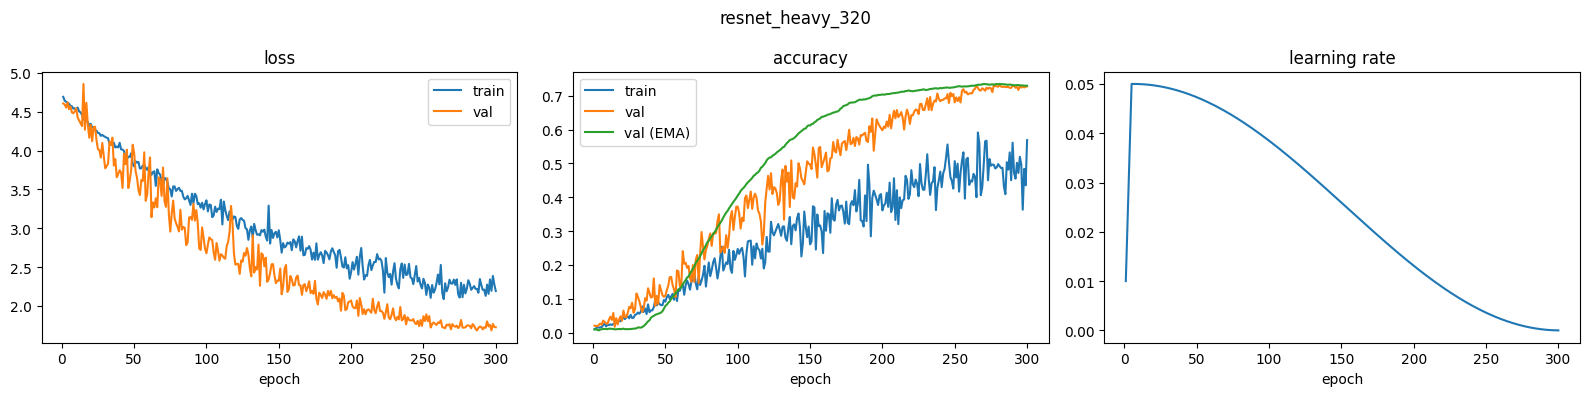

In [9]:
ep = range(1, len(hist["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ep, hist["train_loss"], label="train"); axes[0].plot(ep, hist["val_loss"], label="val")
axes[0].set_title("loss")
axes[1].plot(ep, hist["train_acc"], label="train"); axes[1].plot(ep, hist["val_acc"], label="val")
axes[1].plot(ep, hist["ema_acc"], label="val (EMA)"); axes[1].set_title("accuracy")
axes[2].plot(ep, hist["lr"]); axes[2].set_title("learning rate")
for a in axes[:2]:
    a.legend()
for a in axes:
    a.set_xlabel("epoch")
fig.suptitle(cfg["name"]); plt.tight_layout(); plt.show()

## All runs so far

In [10]:
runs = {p.stem: json.loads(p.read_text()) for p in sorted(RESULTS_DIR.glob("*.json"))}
print(f"{'run':35s} {'best val acc':>12s}")
for name, r in sorted(runs.items(), key=lambda kv: -kv[1]["best_val_acc"]):
    print(f"{name:35s} {r['best_val_acc']:12.3f}")

run                                 best val acc
resnet_heavy_320_seed42                    0.735
ablate_no_se_seed42                        0.575
resnet_best_seed42                         0.561
ablate_no_residual_seed42                  0.553
ablate_no_augment_seed42                   0.465
plain_cnn_aug_seed42                       0.248
plain_cnn_seed42                           0.214
ablate_no_batchnorm_seed42                 0.032


## Test (final model only)

In [11]:
RUN_TEST = True
if RUN_TEST:
    test_dl = DataLoader(Aircraft("test", cfg), 128, num_workers=NUM_WORKERS)
    print(f"test acc {evaluate(model, test_dl, nn.CrossEntropyLoss())[1]:.3f}")

caching test (3333 images) ...
test acc 0.731
